# Exploratory statistical comparison at the reference training sizes

This notebook reads saved results; it does not retrain models or change the input files. It compares the largest evaluated training-plus-validation size for each task. Each metric is analyzed separately, using the saved bootstrap **mean** as the task score. Results are exploratory because there are only four cohort groups, one model fit per task and size, and the selected tasks do not constitute a random sample of clinical problems.

**Shared-subject tasks:** Heart and Diabetes-H are different prediction objectives from related subjects; Obesity and Obesity-Bin are different objectives from the same dataset. They are kept separate when ranking models within tasks. For cohort summaries and tests, each pair receives equal weight within one group. Grouping limits double-counting; it does not prove that the four resulting groups are independent.

For reproducibility the notebook requires complete results for the selected models, tasks, and metrics, and checks that models for a task used the same stored training indices, test indices, and test labels. Only trusted pickle files should be loaded.

In [1]:
from pathlib import Path
import pickle
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'results_metrics').is_dir() and (PROJECT_ROOT.parent / 'results_metrics').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS_DIR = PROJECT_ROOT / 'results_metrics' / 'current'

TASK_SIZES = {
    'heart': 1000,
    'diabetes_h': 1000,
    'diabetes_130': 1000,
    'obesity': 1000,
    'obesity_bin': 1000,
    'breast_cancer': 455,
}
COHORT_GROUPS = {
    'Heart + Diabetes-H': ['heart', 'diabetes_h'],
    'Diabetes-130': ['diabetes_130'],
    'Obesity + Obesity-Bin': ['obesity', 'obesity_bin'],
    'Breast Cancer': ['breast_cancer'],
}
MODELS = ['mlp', 'lr', 'rf', 'nam', 'kan', 'kan_gam', 'ebm', 'xgboost', 'lightgbm']
MODEL_LABELS = {
    'mlp': 'MLP', 'lr': 'LR', 'rf': 'RF', 'nam': 'NAM',
    'kan': 'Logistic-KAN', 'kan_gam': 'KAAM', 'ebm': 'EBM',
    'xgboost': 'XGBoost', 'lightgbm': 'LightGBM',
}
# These are the original main-table metrics. True means higher is better.
METRICS = {
    'accuracy': {'label': 'Accuracy', 'higher_is_better': True},
    'roc_auc': {'label': 'ROC-AUC', 'higher_is_better': True},
    'f1': {'label': 'F1', 'higher_is_better': True},
    'precision': {'label': 'Precision', 'higher_is_better': True},
    'recall': {'label': 'Recall', 'higher_is_better': True},
}
ALPHA = 0.05
FIGURE_DIR = PROJECT_ROOT / 'results_metrics' / 'figures' / 'statistical'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


## Table 1. Tasks, sizes, and cohort groups

This table documents which result file is used for each task. The sample size is the number of observations allocated to training **plus internal validation**, excluding held-out test data. Breast Cancer uses 455 development records; all other tasks use 1,000. The two related pairs have distinct targets and are combined only when forming cohort-level summaries and tests.

In [2]:
task_groups = {task: group for group, tasks in COHORT_GROUPS.items() for task in tasks}
if len(task_groups) != sum(map(len, COHORT_GROUPS.values())) or set(task_groups) != set(TASK_SIZES):
    raise ValueError('Cohort groups must contain every selected task exactly once.')
if len(MODELS) < 3 or len(set(MODELS)) != len(MODELS) or not METRICS:
    raise ValueError('Select at least three unique models and at least one metric.')
if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f'Results directory not found: {RESULTS_DIR}')

task_table = pd.DataFrame([
    {'Task': task, 'Train + validation N': size, 'Cohort group': task_groups[task]}
    for task, size in TASK_SIZES.items()
])
display(task_table)

,Task,Train + validation N,Cohort group
0,heart,1000,Heart + Diabetes-H
1,diabetes_h,1000,Heart + Diabetes-H
2,diabetes_130,1000,Diabetes-130
3,obesity,1000,Obesity + Obesity-Bin
4,obesity_bin,1000,Obesity + Obesity-Bin
5,breast_cancer,455,Breast Cancer


## Table 2. Input coverage

Every selected model must have a saved result for every task at its specified size. This table identifies missing files or metrics. A result must include stored training indices, test indices and test labels; these are checked across models within the same task before any comparison. The notebook does not silently fill missing results or change the set of models between tasks.

In [3]:
records, problems = [], []
reference_splits = {}
for task, size in TASK_SIZES.items():
    for model in MODELS:
        path = RESULTS_DIR / str(size) / task / f'{model}.pkl'
        if not path.is_file():
            problems.append({'Task': task, 'N': size, 'Model': model, 'Problem': 'Result file not found'})
            continue
        with path.open('rb') as file:
            result = pickle.load(file)
        missing_fields = [key for key in ('train_indices', 'test_indices', 'y_test', 'metric_mean') if key not in result]
        if missing_fields:
            problems.append({'Task': task, 'N': size, 'Model': model, 'Problem': f'Missing fields: {missing_fields}'})
            continue
        if result.get('dataset') != task or result.get('model') != model or result.get('train_size') != size:
            problems.append({'Task': task, 'N': size, 'Model': model, 'Problem': 'Result metadata does not match the requested combination'})
            continue
        split = tuple(np.asarray(result[key]).reshape(-1) for key in ('train_indices', 'test_indices', 'y_test'))
        if task in reference_splits:
            if not all(np.array_equal(left, right) for left, right in zip(reference_splits[task], split)):
                problems.append({'Task': task, 'N': size, 'Model': model, 'Problem': 'Training/test indices or test labels differ from the reference model'})
                continue
        else:
            reference_splits[task] = split
        for metric in METRICS:
            value = result['metric_mean'].get(metric)
            if value is None or not np.isfinite(value):
                problems.append({'Task': task, 'N': size, 'Model': model, 'Problem': f'Missing or non-finite metric: {metric}'})
                continue
            records.append({'task': task, 'size': size, 'group': task_groups[task], 'model': model, 'metric': metric, 'value': float(value)})

coverage = pd.DataFrame(problems, columns=['Task', 'N', 'Model', 'Problem'])
if coverage.empty:
    print(f'Complete coverage: {len(TASK_SIZES)} tasks × {len(MODELS)} models × {len(METRICS)} metrics.')
else:
    display(coverage)
    raise ValueError('Complete the missing or inconsistent results, or revise the selection, before continuing.')
scores = pd.DataFrame(records)

Complete coverage: 6 tasks × 9 models × 5 metrics.


## Table 3. Cohort-level scores used by Wilcoxon and Friedman

For each metric and model, the score for a related pair is the arithmetic mean of its two task scores. The other groups retain their individual task score. Thus each model has four paired scores per metric. These values are used for both statistical tests.

This is an explicitly chosen summary across different objectives. In particular, binary F1 refers to the positive class while multiclass F1 is support-weighted, and the corresponding precision/recall definitions also differ. Arithmetic means across tasks should therefore be interpreted cautiously. The table remains descriptive even when scores share the same numeric scale.

In [4]:
group_scores = (
    scores.groupby(['metric', 'group', 'model'], sort=False)['value']
    .mean()
    .unstack('model')
    .reindex(columns=MODELS)
)
expected_groups = pd.MultiIndex.from_product([list(METRICS), list(COHORT_GROUPS)], names=['metric', 'group'])
group_scores = group_scores.reindex(expected_groups)
if group_scores.isna().any().any():
    raise ValueError('A cohort/model/metric score is missing.')
display(group_scores.rename(columns=MODEL_LABELS).rename_axis(index=['Metric', 'Cohort group']).round(4))

model                               MLP      LR  ...  XGBoost  LightGBM
Metric    Cohort group                           ...                   
accuracy  Heart + Diabetes-H     0.8641  0.7714  ...   0.8578    0.8664
          Diabetes-130           0.5000  0.5535  ...   0.5384    0.5366
          Obesity + Obesity-Bin  0.8618  0.8593  ...   0.9870    0.9869
          Breast Cancer          0.9568  0.9567  ...   0.9566    0.9390
roc_auc   Heart + Diabetes-H     0.6922  0.7841  ...   0.7639    0.7739
          Diabetes-130           0.5229  0.6218  ...   0.6005    0.6156
          Obesity + Obesity-Bin  0.9704  0.9621  ...   0.9996    0.9998
          Breast Cancer          0.9903  0.9940  ...   0.9835    0.9832
f1        Heart + Diabetes-H     0.4072  0.5797  ...   0.4917    0.5019
          Diabetes-130           0.4600  0.5072  ...   0.5049    0.5053
          Obesity + Obesity-Bin  0.8556  0.8517  ...   0.9866    0.9867
          Breast Cancer          0.9659  0.9653  ...   0.9652    0.9504
precision Heart + Diabetes-H     0.4611  0.5262  ...   0.5532    0.5993
          Diabetes-130           0.4406  0.5185  ...   0.4960    0.4914
          Obesity + Obesity-Bin  0.8642  0.8580  ...   0.9870    0.9849
          Breast Cancer          0.9592  0.9720  ...   0.9720    0.9712
recall    Heart + Diabetes-H     0.4202  0.7627  ...   0.4753    0.4817
          Diabetes-130           0.5000  0.5535  ...   0.5384    0.5366
          Obesity + Obesity-Bin  0.8540  0.8616  ...   0.9867    0.9893
          Breast Cancer          0.9731  0.9591  ...   0.9590    0.9312

[20 rows x 9 columns]

## Table 4. Four reciprocal-rank contributions

For each metric, models are ranked **within each task** after rounding saved mean scores to two decimal places. Better values receive rank 1; ties at two decimals receive average ranks. Statistical tests continue to use unrounded scores. The reciprocal of the task rank is computed first. The two reciprocal ranks for a related pair are then averaged within its cohort group. The table therefore shows the four inputs to each model's cohort-weighted MRR.

These are descriptive rankings, not statistical tests. They do not measure the magnitude or significance of a performance difference. The rankings here are formed within tasks; the tests below instead rank or compare the cohort-averaged metric scores shown in Table 3.

In [5]:
task_ranks = scores.copy()
task_ranks['ranking_value'] = task_ranks['value'].round(2)
for metric, settings in METRICS.items():
    mask = task_ranks['metric'] == metric
    task_ranks.loc[mask, 'rank'] = (
        task_ranks.loc[mask].groupby('task')['ranking_value']
        .rank(method='average', ascending=not settings['higher_is_better'])
    )
task_ranks['reciprocal_rank'] = 1.0 / task_ranks['rank']
cohort_rr = (
    task_ranks.groupby(['metric', 'group', 'model'], sort=False)['reciprocal_rank']
    .mean()
    .unstack('model')
    .reindex(index=expected_groups, columns=MODELS)
)
display(cohort_rr.rename(columns=MODEL_LABELS).rename_axis(index=['Metric', 'Cohort group']).round(4))

model                               MLP      LR  ...  XGBoost  LightGBM
Metric    Cohort group                           ...                   
accuracy  Heart + Diabetes-H     0.2338  0.1111  ...   0.1667    0.2338
          Diabetes-130           0.1111  0.2000  ...   0.1538    0.1538
          Obesity + Obesity-Bin  0.1250  0.2222  ...   0.4167    0.5000
          Breast Cancer          0.2500  0.2500  ...   0.2500    0.1429
roc_auc   Heart + Diabetes-H     0.1181  0.2159  ...   0.1429    0.1818
          Diabetes-130           0.1111  0.2857  ...   0.1667    0.2857
          Obesity + Obesity-Bin  0.1250  0.1806  ...   0.2679    0.2679
          Breast Cancer          0.3333  0.3333  ...   0.1538    0.1538
f1        Heart + Diabetes-H     0.1213  0.5000  ...   0.1833    0.4333
          Diabetes-130           0.1250  0.4000  ...   0.2000    0.4000
          Obesity + Obesity-Bin  0.1250  0.1667  ...   0.4444    0.4444
          Breast Cancer          0.2500  0.2500  ...   0.2500    0.1429
precision Heart + Diabetes-H     0.1213  0.5714  ...   0.2576    0.3409
          Diabetes-130           0.1111  0.5000  ...   0.2000    0.1667
          Obesity + Obesity-Bin  0.1250  0.1667  ...   0.4444    0.4444
          Breast Cancer          0.1429  0.3333  ...   0.3333    0.3333
recall    Heart + Diabetes-H     0.1534  0.2222  ...   0.1576    0.1818
          Diabetes-130           0.1111  0.2000  ...   0.1538    0.1538
          Obesity + Obesity-Bin  0.1250  0.3056  ...   0.4333    0.5833
          Breast Cancer          0.4000  0.2000  ...   0.2000    0.1333

[20 rows x 9 columns]

## Table 5. Cohort-weighted MRR by metric and overall

Each metric's MRR is the mean of the four cohort-level reciprocal-rank contributions in Table 4. The **Overall** row is the equal-weight mean across the selected metrics, as in the earlier combined MRR. A larger MRR indicates more frequent high ranks and gives a large advantage to rank 1 over rank 2.

The overall row weights correlated metrics separately. For multiclass tasks, weighted recall equals accuracy; the two are nevertheless both included when selected here to retain the historical set of metrics. MRR is descriptive and depends on the selected models, tasks, metrics, and tie rule.

In [6]:
mrr = cohort_rr.groupby(level='metric', sort=False).mean().reindex(METRICS)
mrr.index = [METRICS[metric]['label'] for metric in mrr.index]
mrr.loc['Overall'] = mrr.mean(axis=0)
display(mrr.rename(columns=MODEL_LABELS).rename_axis(index='Metric').round(4))

model,MLP,LR,RF,NAM,Logistic-KAN,KAAM,EBM,XGBoost,LightGBM
Metric,,,,,,,,,
Accuracy,0.1800,0.1958,0.1406,0.3262,0.2923,0.2923,0.5811,0.2468,0.2576
ROC-AUC,0.1719,0.2539,0.2062,0.2715,0.2798,0.2842,0.5253,0.1828,0.2223
F1,0.1553,0.3292,0.3678,0.1262,0.3815,0.3190,0.3791,0.2694,0.3552
Precision,0.1251,0.3929,0.1937,0.1567,0.2834,0.2698,0.5588,0.3088,0.3213
Recall,0.1974,0.2319,0.1531,0.2567,0.3714,0.3589,0.5364,0.2362,0.2631
Overall,0.1659,0.2807,0.2123,0.2275,0.3217,0.3048,0.5161,0.2488,0.2839


## Table 6. One-sided paired Wilcoxon comparisons across cohort groups

For each metric, the reference is selected as the model with the best arithmetic mean of the four cohort scores in Table 3; all other models are compared with it using a one-sided paired Wilcoxon signed-rank test in the direction “candidate is worse”. Models remain paired by cohort name. P-values are adjusted with Holm separately within each metric; the reference is not included in the correction.

**Exploratory limitation:** the reference is chosen from the same data, so these p-values and Holm adjustments do not fully correct for selecting the winner. Four cohort groups provide very low power. With four non-zero differences, the ideal minimum one-sided exact p-value is 0.0625 before correction; zeros and ties alter the null distribution. `*` means only that the corrected p-value is at least the chosen alpha; it does **not** establish equivalence. No marker is assigned to a missing test. The displayed p-values use SciPy's `method='auto'`, including its handling of zeros and ties. See [SciPy Wilcoxon documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html).

In [7]:
wilcoxon_rows = []
for metric, settings in METRICS.items():
    matrix = group_scores.loc[metric].reindex(index=COHORT_GROUPS, columns=MODELS)
    direction = 1.0 if settings['higher_is_better'] else -1.0
    oriented = direction * matrix
    reference = oriented.mean(axis=0).idxmax()
    start = len(wilcoxon_rows)
    for model in MODELS:
        if model == reference:
            continue
        differences = (oriented[model] - oriented[reference]).to_numpy()
        n_nonzero = int(np.count_nonzero(differences))
        if n_nonzero == 0:
            statistic, p_value, test_note = 0.0, 1.0, 'All paired differences are zero'
        else:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                test = stats.wilcoxon(differences, alternative='less', zero_method='wilcox', method='auto')
            statistic, p_value = float(test.statistic), float(test.pvalue)
            test_note = '; '.join(str(item.message) for item in caught)
        wilcoxon_rows.append({
            'Metric': settings['label'], 'Model': MODEL_LABELS[model],
            'Reference': MODEL_LABELS[reference], 'Cohorts': len(matrix),
            'Non-zero differences': n_nonzero,
            'Mean difference (candidate - reference)': float((matrix[model] - matrix[reference]).mean()),
            'W': statistic, 'p (raw)': p_value, 'Note': test_note,
        })
    metric_rows = wilcoxon_rows[start:]
    valid = [i for i, row in enumerate(metric_rows) if np.isfinite(row['p (raw)'])]
    if valid:
        adjusted = multipletests([metric_rows[i]['p (raw)'] for i in valid], alpha=ALPHA, method='holm')[1]
        for i, p_adjusted in zip(valid, adjusted):
            metric_rows[i]['p (Holm)'] = float(p_adjusted)
            metric_rows[i]['Not rejected'] = '*' if p_adjusted >= ALPHA else ''
wilcoxon_table = pd.DataFrame(wilcoxon_rows)
display(wilcoxon_table.round(4))

,Metric,Model,Reference,Cohorts,Non-zero differences,Mean difference (candidate - reference),W,p (raw),Note,p (Holm),Not rejected
0,Accuracy,MLP,EBM,4,4,-0.0506,0.0,0.0625,,0.5000,*
1,Accuracy,LR,EBM,4,4,-0.0611,0.0,0.0625,,0.5000,*
2,Accuracy,RF,EBM,4,4,-0.0291,0.0,0.0625,,0.5000,*
3,Accuracy,NAM,EBM,4,4,-0.0885,0.0,0.0625,,0.5000,*
4,Accuracy,Logistic-KAN,EBM,4,4,-0.0224,2.0,0.1875,,0.5625,*
5,Accuracy,KAAM,EBM,4,4,-0.0223,2.0,0.1875,,0.5625,*
6,Accuracy,XGBoost,EBM,4,4,-0.0113,1.0,0.1250,,0.5000,*
7,Accuracy,LightGBM,EBM,4,4,-0.0140,2.0,0.1875,,0.5625,*
8,ROC-AUC,MLP,EBM,4,4,-0.0616,0.0,0.0625,,0.5000,*
9,ROC-AUC,LR,EBM,4,4,-0.0151,1.0,0.1250,,0.6250,*


## Table 7. Friedman and Iman–Davenport tests

For each metric, the Friedman test compares all selected models on the four cohort-level scores from Table 3. SciPy computes the Friedman statistic with a correction for within-block ties. The Iman–Davenport transformation is

$$F_F = \frac{(N-1)\chi_F^2}{N(k-1)-\chi_F^2},$$

with degrees of freedom $k-1$ and $(k-1)(N-1)$, where $N$ is the number of cohort groups and $k$ is the number of models. These formulas correct the previous implementation's missing denominator term and incorrect degrees of freedom. [Demšar, 2006](https://www.jmlr.org/papers/volume7/demsar06a/demsar06a.pdf).

Both displayed p-values use asymptotic reference distributions and are **exploratory and unreliable with only four groups**. If all models tie within every group the test is undefined and reported as `NaN`. A significant omnibus result does not identify which pairs differ. No test is formed by treating different metrics or training sizes as independent datasets.

In [8]:
friedman_rows = []
for metric, settings in METRICS.items():
    matrix = group_scores.loc[metric].reindex(index=COHORT_GROUPS, columns=MODELS)
    values = matrix.to_numpy(dtype=float)
    n_groups, n_models = values.shape
    if np.all(np.ptp(values, axis=1) == 0):
        chi_square, p_friedman = np.nan, np.nan
        f_statistic, p_iman = np.nan, np.nan
        note = 'All models tie within every cohort group; test undefined.'
    else:
        friedman = stats.friedmanchisquare(*[values[:, i] for i in range(n_models)])
        chi_square, p_friedman = float(friedman.statistic), float(friedman.pvalue)
        denominator = n_groups * (n_models - 1) - chi_square
        if np.isclose(denominator, 0.0, atol=1e-12):
            f_statistic, p_iman = np.inf, 0.0
        elif denominator < 0:
            raise ValueError(f'Invalid Iman–Davenport denominator for {metric}: {denominator}')
        else:
            f_statistic = (n_groups - 1) * chi_square / denominator
            p_iman = float(stats.f.sf(f_statistic, n_models - 1, (n_models - 1) * (n_groups - 1)))
        note = 'Asymptotic approximation; only four cohort groups.'
    friedman_rows.append({
        'Metric': settings['label'], 'Cohorts': n_groups, 'Models': n_models,
        'Friedman chi-square': chi_square, 'Friedman df': n_models - 1,
        'Friedman p': p_friedman, 'Iman–Davenport F': f_statistic,
        'F df1': n_models - 1, 'F df2': (n_models - 1) * (n_groups - 1),
        'Iman–Davenport p': p_iman, 'Note': note,
    })
friedman_table = pd.DataFrame(friedman_rows)
display(friedman_table.round(4))

,Metric,Cohorts,Models,Friedman chi-square,Friedman df,Friedman p,Iman–Davenport F,F df1,F df2,Iman–Davenport p,Note
0,Accuracy,4,9,9.0021,8,0.3421,1.1743,8,24,0.3542,Asymptotic approximation; only four cohort gro...
1,ROC-AUC,4,9,10.2000,8,0.2513,1.4037,8,24,0.2452,Asymptotic approximation; only four cohort gro...
2,F1,4,9,12.2088,8,0.1421,1.8506,8,24,0.1164,Asymptotic approximation; only four cohort gro...
3,Precision,4,9,18.7557,8,0.0162,4.2484,8,24,0.0027,Asymptotic approximation; only four cohort gro...
4,Recall,4,9,12.5094,8,0.1299,1.9254,8,24,0.1026,Asymptotic approximation; only four cohort gro...


## Interpretation

The six tasks are retained for within-task ranking, but the two shared-subject pairs each contribute a single averaged group to MRR and to the tests. The reference comparison uses 1,000 development records for five tasks and 455 for Breast Cancer. Grouping does not prove independence between the resulting cohorts.

The statistical analyses are conditional on the saved trained models and selected test sets; they do not quantify variability across retraining or random splits. With four groups, the Wilcoxon test has a very coarse p-value resolution and the Friedman/Iman–Davenport asymptotic approximations are unreliable. A non-significant result is not evidence of equivalence. Report these tables as exploratory and retain the task-level metrics and confidence intervals alongside them.

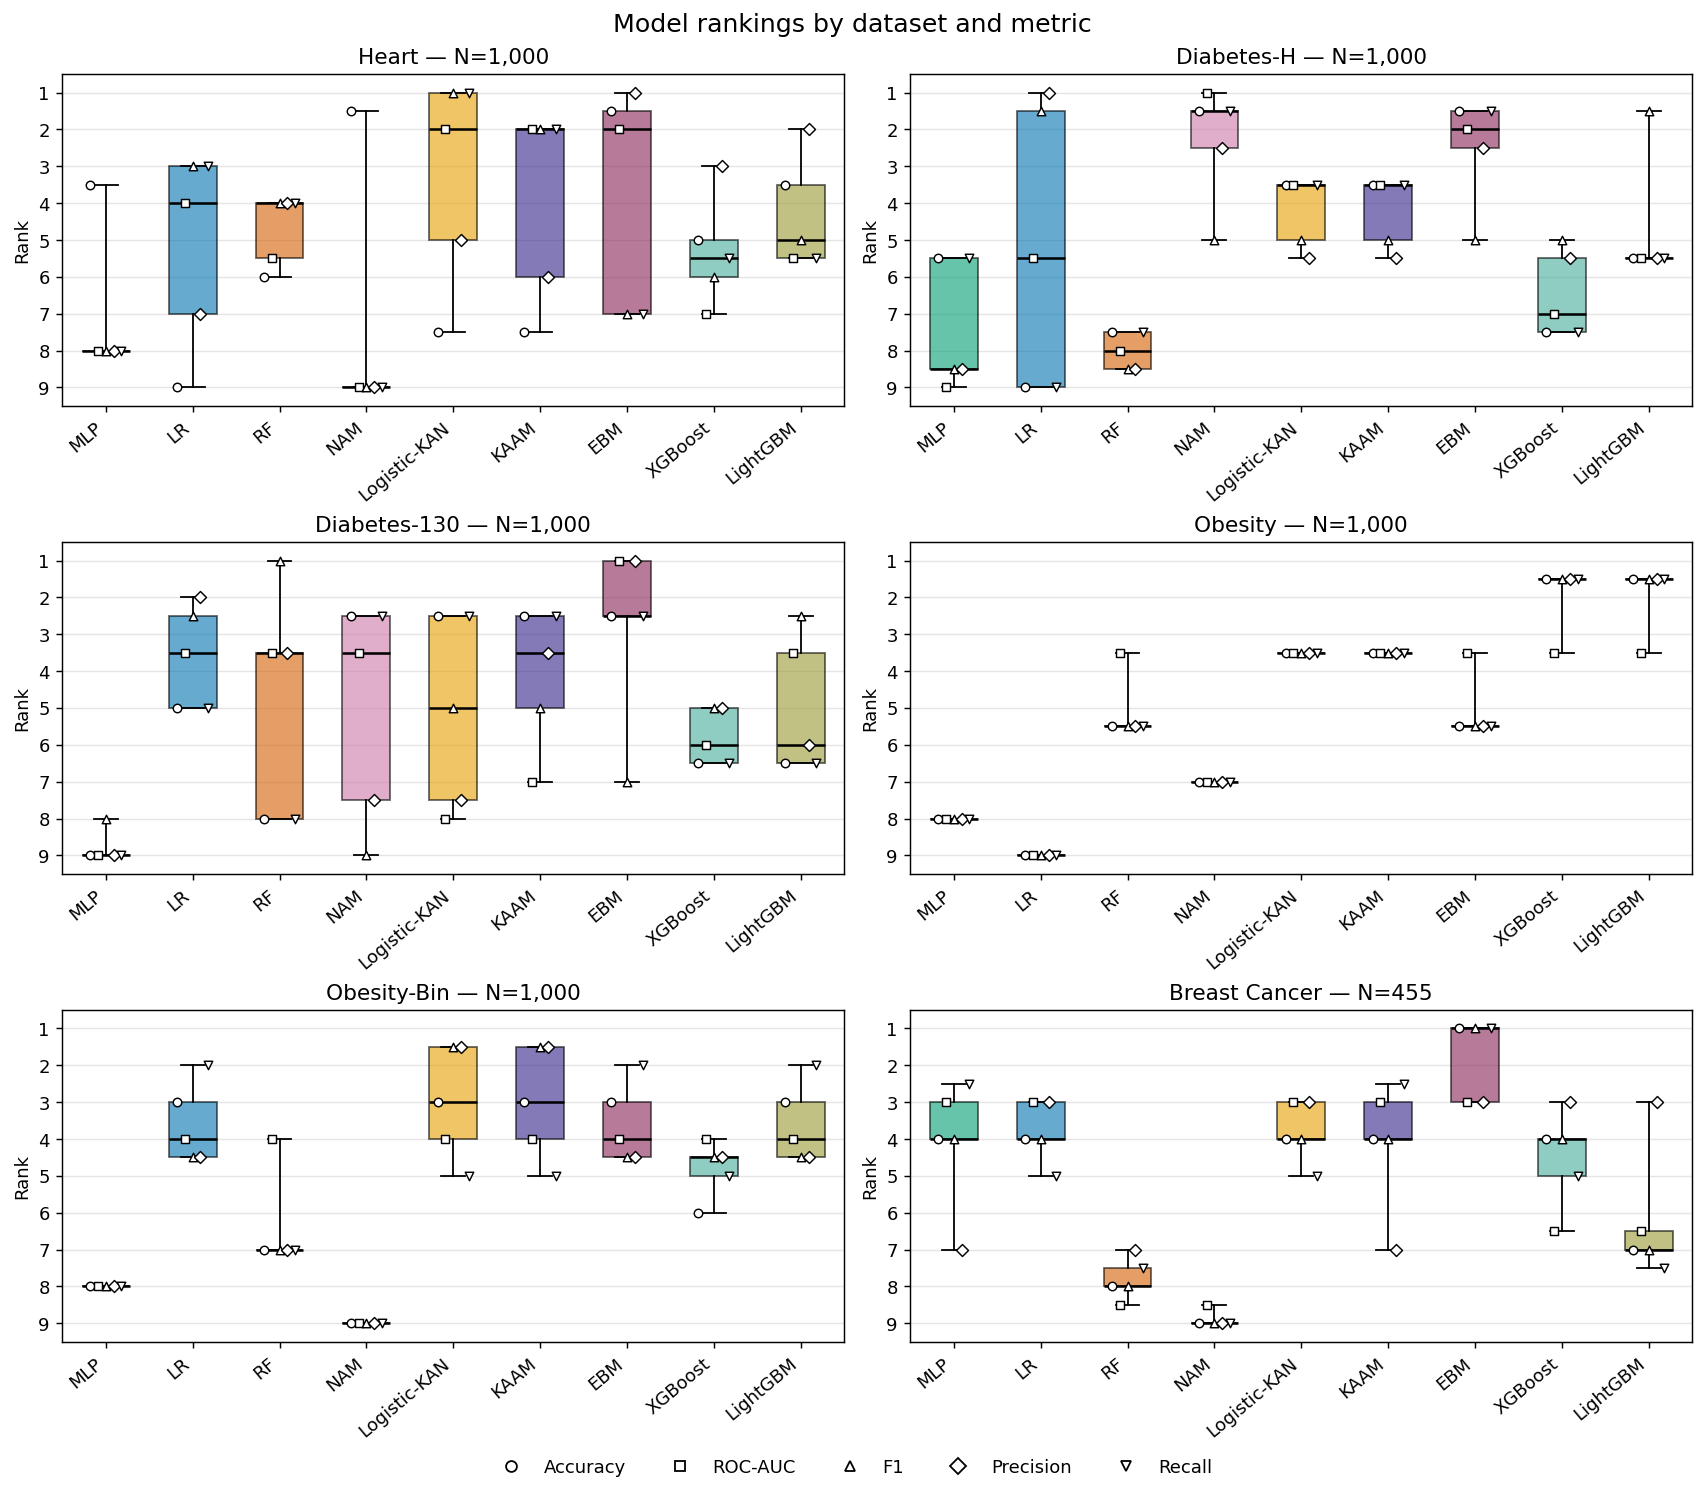

In [9]:
# Rankings by dataset: each box summarizes the five metric-specific ranks.
import math
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODEL_COLORS = {
    'lr': '#0072B2', 'rf': '#D55E00', 'mlp': '#009E73',
    'nam': '#CC79A7', 'kan': '#E69F00', 'kan_gam': '#332288',
    'ebm': '#882255', 'xgboost': '#44AA99', 'lightgbm': '#999933',
}
DATASET_LABELS = {
    'heart': 'Heart', 'diabetes_h': 'Diabetes-H', 'diabetes_130': 'Diabetes-130',
    'obesity': 'Obesity', 'obesity_bin': 'Obesity-Bin', 'breast_cancer': 'Breast Cancer',
}
metric_markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>']
if len(METRICS) > len(metric_markers):
    raise ValueError('Add markers for the selected metrics.')
if any(model not in MODEL_COLORS for model in MODELS):
    raise ValueError('Add a color for every selected model.')

paper_style = {
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.edgecolor': 'black',
    'axes.labelcolor': 'black', 'text.color': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
    'grid.color': '#cccccc', 'font.size': 10,
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}
tasks = list(TASK_SIZES)
ncols = 2
nrows = math.ceil(len(tasks) / ncols)
with plt.rc_context(paper_style):
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.8 * nrows),
                             squeeze=False, constrained_layout=True, facecolor='white')
    for ax, task in zip(axes.flat, tasks):
        ax.set_facecolor('white')
        positions = np.arange(1, len(MODELS) + 1)
        for position, model in zip(positions, MODELS):
            ranks = task_ranks[(task_ranks['task'] == task) & (task_ranks['model'] == model)]
            ranks = ranks.set_index('metric').reindex(list(METRICS))
            if ranks['rank'].isna().any():
                raise ValueError(f'Missing rankings for {task}/{model}.')
            ax.boxplot(
                ranks['rank'].to_numpy(dtype=float), positions=[position], widths=0.55,
                patch_artist=True, whis=(0, 100), showfliers=False,
                boxprops={'facecolor': MODEL_COLORS[model], 'edgecolor': 'black', 'alpha': 0.6},
                medianprops={'color': 'black', 'linewidth': 1.4},
                whiskerprops={'color': 'black'}, capprops={'color': 'black'},
            )
            offsets = np.linspace(-0.18, 0.18, len(METRICS))
            for offset, marker, rank in zip(offsets, metric_markers, ranks['rank']):
                ax.scatter(position + offset, rank, marker=marker, s=22,
                           facecolor='white', edgecolor='black', linewidth=0.8, zorder=3)
        ax.set_title(f"{DATASET_LABELS.get(task, task)} — N={TASK_SIZES[task]:,}", color='black')
        ax.set_xticks(positions, [MODEL_LABELS.get(model, model) for model in MODELS],
                      rotation=40, ha='right', color='black')
        ax.set_yticks(np.arange(1, len(MODELS) + 1))
        ax.set_ylim(len(MODELS) + 0.5, 0.5)
        ax.set_ylabel('Rank', color='black')
        ax.tick_params(colors='black')
        ax.grid(axis='y', alpha=0.5)
        ax.set_axisbelow(True)
        for spine in ax.spines.values():
            spine.set_color('black')
    for ax in axes.flat[len(tasks):]:
        ax.set_visible(False)
    handles = [Line2D([0], [0], marker=marker, linestyle='none', color='black',
                      markerfacecolor='white', markersize=6, label=settings['label'])
               for marker, settings in zip(metric_markers, METRICS.values())]
    fig.legend(handles=handles, loc='outside lower center', ncol=min(5, len(handles)), frameon=False)
    fig.suptitle('Model rankings by dataset and metric', color='black', fontsize=14)
    fig.savefig(FIGURE_DIR / 'rankings_by_dataset.pdf', bbox_inches='tight', facecolor='white')
    fig.savefig(FIGURE_DIR / 'rankings_by_dataset.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
# Optional: fig.savefig('ranking_boxplots.pdf', bbox_inches='tight', facecolor='white')

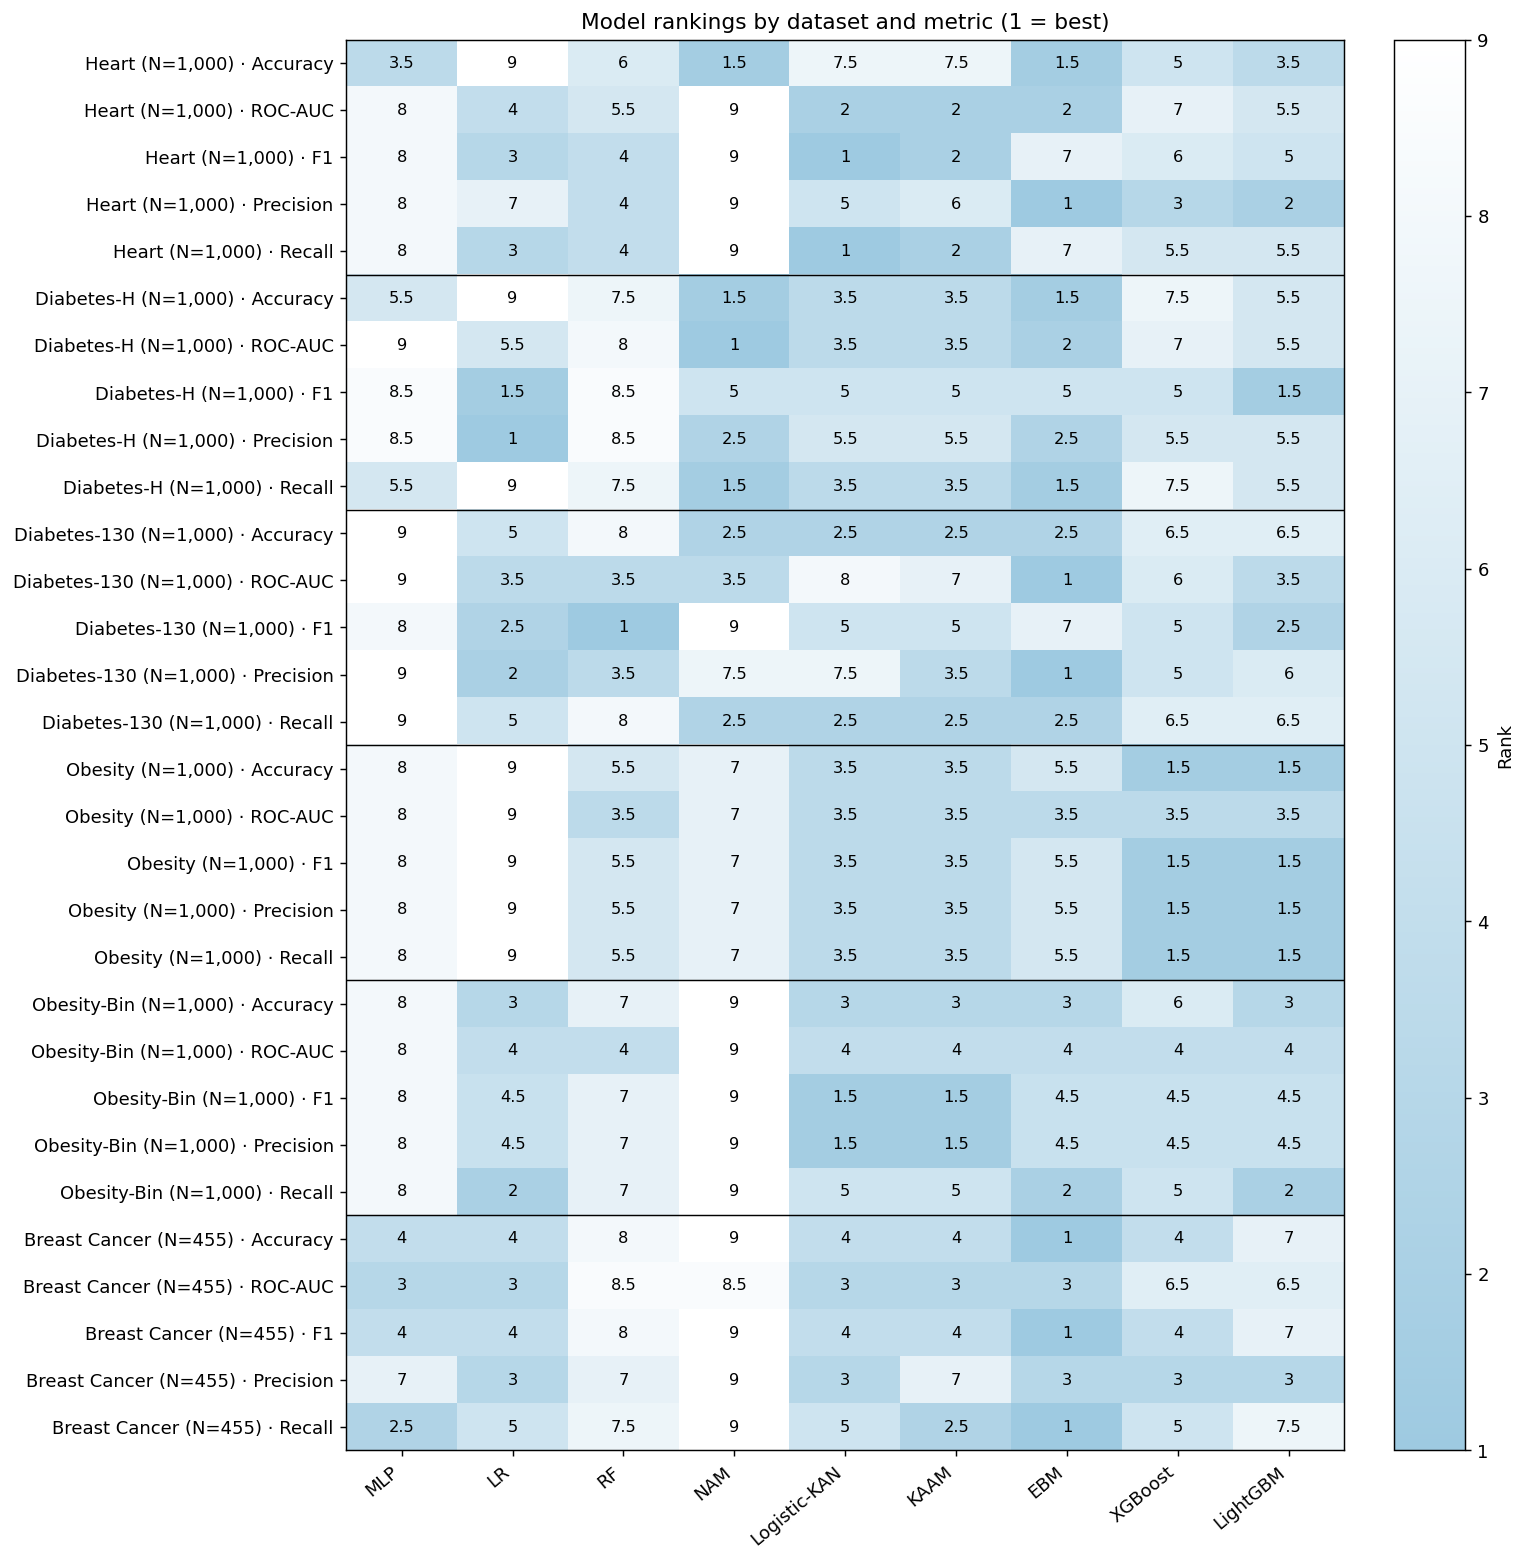

In [10]:
# Each cell is one dataset–metric ranking; tie ranks may be fractional.
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ranking_matrix = (
    task_ranks.pivot(index=['task', 'metric'], columns='model', values='rank')
    .reindex(index=pd.MultiIndex.from_product([list(TASK_SIZES), list(METRICS)],
                                              names=['task', 'metric']),
             columns=MODELS)
)
if ranking_matrix.isna().any().any():
    raise ValueError('The ranking heatmap requires every selected task, metric and model.')
row_labels = [
    f"{DATASET_LABELS.get(task, task)} (N={TASK_SIZES[task]:,}) · {METRICS[metric]['label']}"
    for task, metric in ranking_matrix.index
]
with plt.rc_context(paper_style):
    fig_heatmap, ax = plt.subplots(figsize=(max(9, 0.85 * len(MODELS) + 4),
                                            max(6, 0.33 * len(row_labels) + 2)),
                                    constrained_layout=True, facecolor='white')
    ax.set_facecolor('white')
    heatmap = ax.imshow(ranking_matrix.to_numpy(dtype=float), cmap=LinearSegmentedColormap.from_list('light_rank', ['#9ecae1', '#ffffff']),
                        vmin=1, vmax=len(MODELS), aspect='auto')
    ax.set_xticks(np.arange(len(MODELS)),
                  [MODEL_LABELS.get(model, model) for model in MODELS],
                  rotation=40, ha='right', color='black')
    ax.set_yticks(np.arange(len(row_labels)), row_labels, color='black')
    ax.tick_params(colors='black')
    ax.set_title('Model rankings by dataset and metric (1 = best)', color='black')
    midpoint = (1 + len(MODELS)) / 2
    for i in range(len(row_labels)):
        for j in range(len(MODELS)):
            rank = float(ranking_matrix.iloc[i, j])
            ax.text(j, i, f'{rank:g}', ha='center', va='center',
                    color='black', fontsize=9)
    for boundary in range(len(METRICS), len(row_labels), len(METRICS)):
        ax.axhline(boundary - 0.5, color='black', linewidth=0.8)
    for spine in ax.spines.values():
        spine.set_color('black')
    colorbar = fig_heatmap.colorbar(heatmap, ax=ax, ticks=np.arange(1, len(MODELS) + 1))
    colorbar.set_label('Rank', color='black')
    colorbar.ax.tick_params(colors='black')
    fig_heatmap.savefig(FIGURE_DIR / 'ranking_heatmap.pdf', bbox_inches='tight', facecolor='white')
    fig_heatmap.savefig(FIGURE_DIR / 'ranking_heatmap.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
# Optional: fig_heatmap.savefig('ranking_heatmap.pdf', bbox_inches='tight', facecolor='white')

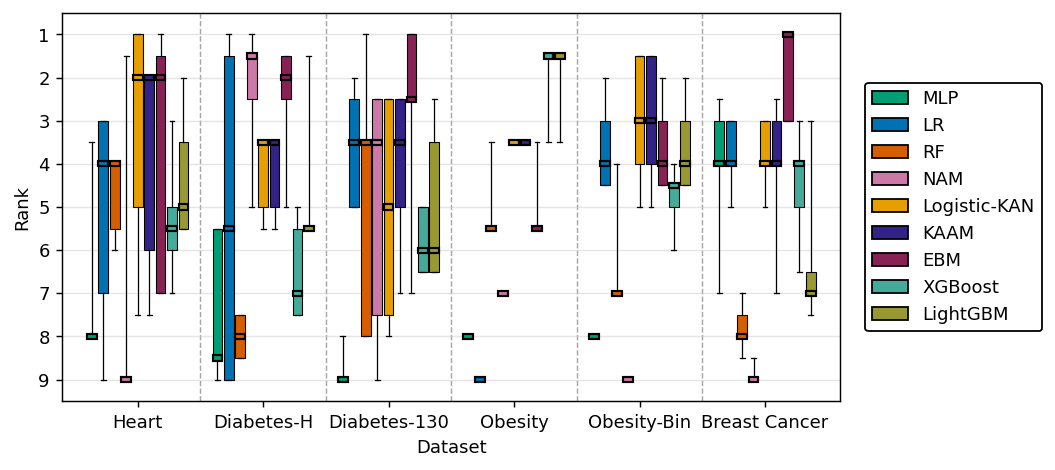

In [11]:
# Combined paper figure: one dataset group, one colored box per model.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

with plt.rc_context(paper_style):
    fig_total, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True, facecolor='white')
    ax.set_facecolor('white')
    dataset_positions = np.arange(len(TASK_SIZES))
    group_width = 0.82
    box_width = group_width / len(MODELS)
    for dataset_position, task in zip(dataset_positions, TASK_SIZES):
        for model_index, model in enumerate(MODELS):
            ranks = task_ranks[
                (task_ranks['task'] == task) & (task_ranks['model'] == model)
            ].set_index('metric').reindex(list(METRICS))['rank']
            if ranks.isna().any():
                raise ValueError(f'Missing rankings for {task}/{model}.')
            position = dataset_position + (model_index - (len(MODELS) - 1) / 2) * box_width
            ax.boxplot(
                ranks.to_numpy(dtype=float), positions=[position], widths=box_width * 0.85,
                patch_artist=True, whis=(0, 100), showfliers=False,
                boxprops={'facecolor': MODEL_COLORS[model], 'edgecolor': 'black', 'linewidth': 0.6},
                medianprops={'linewidth': 0},
                whiskerprops={'color': 'black', 'linewidth': 0.7},
                capprops={'color': 'black', 'linewidth': 0.7},
            )
            median = float(np.median(ranks.to_numpy(dtype=float)))
            ax.add_patch(Rectangle(
                (position - box_width * 0.85 / 2, median - 0.06),
                box_width * 0.85, 0.12,
                facecolor=MODEL_COLORS[model], edgecolor='black',
                linewidth=1.2, zorder=4,
            ))
    ax.set_xticks(dataset_positions, [DATASET_LABELS.get(task, task) for task in TASK_SIZES],
                  color='black')
    ax.set_xlim(-0.6, len(TASK_SIZES) - 0.4)
    for boundary in np.arange(len(TASK_SIZES) - 1) + 0.5:
        ax.axvline(boundary, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, zorder=0)
    ax.set_yticks(np.arange(1, len(MODELS) + 1))
    ax.set_ylim(len(MODELS) + 0.5, 0.5)
    ax.set_xlabel('Dataset', color='black')
    ax.set_ylabel('Rank', color='black')
    ax.tick_params(colors='black')
    ax.grid(axis='y', alpha=0.5)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color('black')
    handles = [Patch(facecolor=MODEL_COLORS[model], edgecolor='black',
                     label=MODEL_LABELS.get(model, model)) for model in MODELS]
    legend = ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5),
                       ncol=1, frameon=True, facecolor='white', edgecolor='black',
                       framealpha=1)
    for text in legend.get_texts():
        text.set_color('black')
    fig_total.savefig(FIGURE_DIR / 'ranking_boxplots_total.pdf', bbox_inches='tight', facecolor='white')
    fig_total.savefig(FIGURE_DIR / 'ranking_boxplots_total.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
# Optional: fig_total.savefig('ranking_boxplots_total.pdf', bbox_inches='tight', facecolor='white')